# 05 · Impact: how badly, and what burned

**Goal:** go beyond "where" to **how severe** and **what kind of land** burned.

- **Severity:** USGS / Key & Benson (2006) dNBR classes.
- **Vegetation:** Chuvieco (2015) NDVI zones, before vs after.
- **Land cover:** ESA WorldCover (10 m): forest, shrub, grass, crops, built-up.
- **Optional:** your own layers (municipalities, Catastro buildings, Natura 2000).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.patches import Patch
from common import *

idx = {k: read_tif(need(f"{k}.tif", "03"))[0] for k in ("dNBR", "NDVI_pre", "NDVI_post")}
_, transform, crs, _ = read_tif(OUT / "dNBR.tif")
final = read_tif(need("footprint_mask.tif", "04"))[0] == 1
px = CFG["resolution"] ** 2 / 1e6
result = {}

## 1. Reclassify: turning numbers into classes
`np.digitize` puts each value into a "bin" (like sorting exam marks into grades). It is the same as ArcGIS **Reclassify**.

In [2]:
def classify(values, bins):
    c = np.digitize(values, bins).astype("uint8")
    c[~np.isfinite(values)] = 255                  # 255 = no data
    return c


def class_table(cls, labels, inside=None):
    rows = []
    for i, lab in enumerate(labels):
        sel = cls == i
        r = {"class": i, "label": lab, "aoi_km2": round(float(sel.sum() * px), 3)}
        if inside is not None:
            r["in_footprint_km2"] = round(float((sel & inside).sum() * px), 3)
        rows.append(r)
    if inside is not None:
        tot = sum(r["in_footprint_km2"] for r in rows) or 1
        for r in rows:
            r["pct_of_footprint"] = round(100 * r["in_footprint_km2"] / tot, 1)
    return rows

## 2. Burn severity (dNBR)
| dNBR | Class |
|---|---|
| < −0.25 / −0.25…−0.10 | Enhanced regrowth (high / low) |
| −0.10…0.10 | Unburned |
| 0.10…0.27 | Low |
| 0.27…0.44 | Moderate-low |
| 0.44…0.66 | Moderate-high |
| > 0.66 | High |

In [3]:
SEVERITY_BINS = [-0.25, -0.10, 0.10, 0.27, 0.44, 0.66]
SEVERITY_LABELS = ["Enhanced regrowth, high", "Enhanced regrowth, low", "Unburned",
                   "Low severity", "Moderate-low severity", "Moderate-high severity",
                   "High severity"]
SEVERITY_COLORS = ["#1A9850", "#91CF60", "#D9D9D9", "#FEE08B", "#FDAE61", "#F46D43", "#A50026"]

sev = classify(idx["dNBR"], SEVERITY_BINS)
write_tif(OUT / "severity_dNBR.tif", sev, transform, crs, 255, ["USGS dNBR class 0-6"])
result["severity"] = class_table(sev, SEVERITY_LABELS, final)
pd.DataFrame(result["severity"][3:])[["label", "in_footprint_km2", "pct_of_footprint"]]

,label,in_footprint_km2,pct_of_footprint
0,Low severity,172.233,27.9
1,Moderate-low severity,207.303,33.5
2,Moderate-high severity,157.309,25.5
3,High severity,76.397,12.4


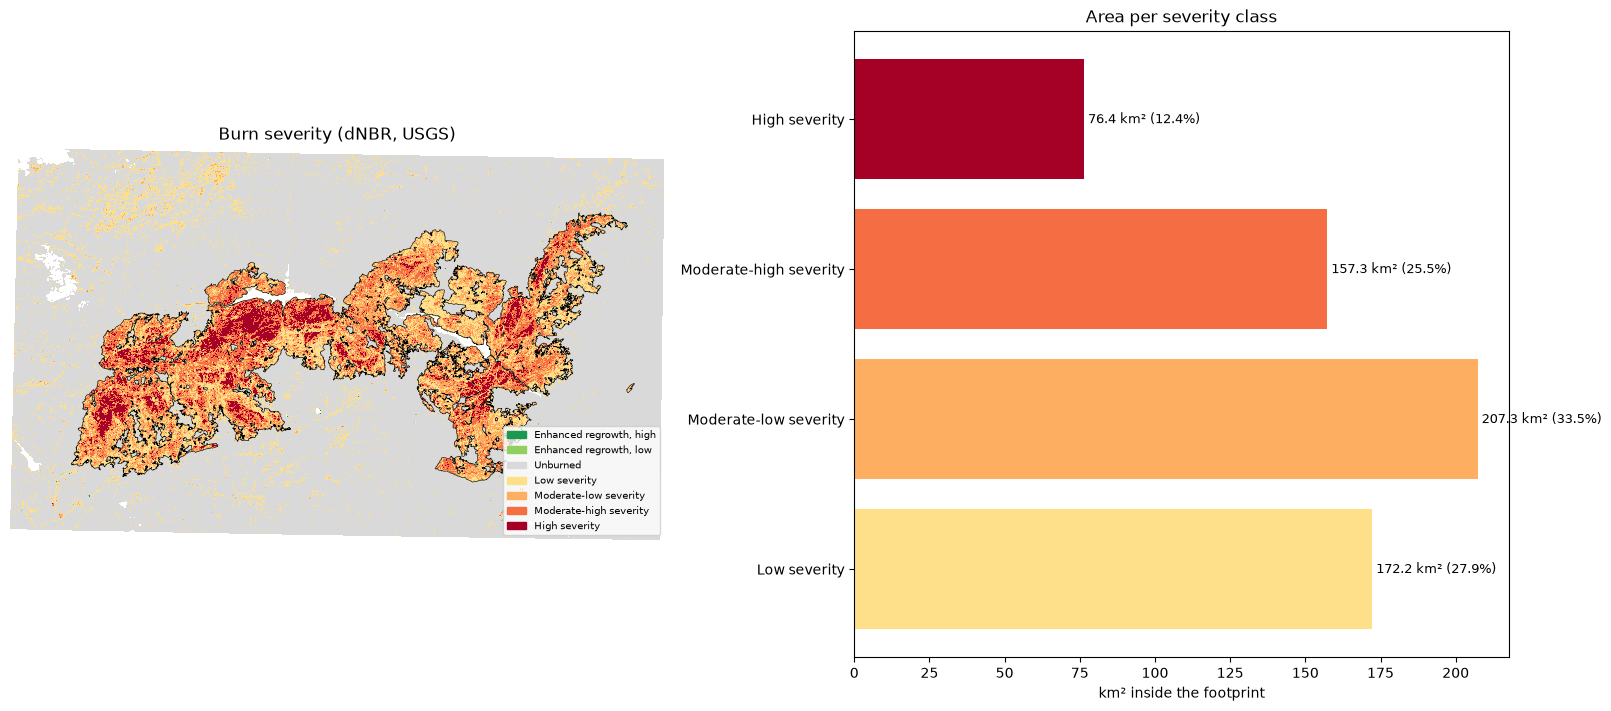

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(16, 7), constrained_layout=True)
ax[0].imshow(np.ma.masked_equal(sev, 255), cmap=ListedColormap(SEVERITY_COLORS),
             norm=BoundaryNorm(np.arange(-.5, 7.5), 7), interpolation="nearest")
ax[0].contour(final, levels=[0.5], colors="black", linewidths=0.4)
ax[0].legend(handles=[Patch(color=c, label=l) for c, l in zip(SEVERITY_COLORS, SEVERITY_LABELS)],
             loc="lower right", fontsize=7)
ax[0].set_title("Burn severity (dNBR, USGS)"); ax[0].set_axis_off()
sv = result["severity"][3:]
ax[1].barh([r["label"] for r in sv], [r["in_footprint_km2"] for r in sv], color=SEVERITY_COLORS[3:])
for i, r in enumerate(sv):
    ax[1].text(r["in_footprint_km2"], i, f" {r['in_footprint_km2']:.1f} km² ({r['pct_of_footprint']}%)",
               va="center", fontsize=9)
ax[1].set_xlabel("km² inside the footprint"); ax[1].set_title("Area per severity class")
fig.savefig(OUT / "step5_severity.png", dpi=130)
plt.show()

## 3. Vegetation zones before vs after (Chuvieco 2015)

In [5]:
NDVI_BINS = [0.0, 0.2, 0.4, 0.6]
NDVI_LABELS = ["Water / shadow (<0)", "Bare soil (0-0.2)", "Sparse veg + soil (0.2-0.4)",
               "Dispersed vegetation (0.4-0.6)", "Dense vegetation (>0.6)"]

t0 = class_table(classify(idx["NDVI_pre"], NDVI_BINS), NDVI_LABELS)
t1 = class_table(classify(idx["NDVI_post"], NDVI_BINS), NDVI_LABELS)
result["ndvi_classes"] = [{"label": a["label"], "pre_km2": a["aoi_km2"], "post_km2": b["aoi_km2"],
                           "change_km2": round(b["aoi_km2"] - a["aoi_km2"], 3)}
                          for a, b in zip(t0, t1)]
pd.DataFrame(result["ndvi_classes"])

,label,pre_km2,post_km2,change_km2
0,Water / shadow (<0),2.411,1.939,-0.472
1,Bare soil (0-0.2),174.987,625.570,450.583
2,Sparse veg + soil (0.2-0.4),1083.061,1303.400,220.339
3,Dispersed vegetation (0.4-0.6),838.266,562.094,-276.172
4,Dense vegetation (>0.6),582.035,187.756,-394.279


## 4. What kind of land burned (ESA WorldCover)
We download the WorldCover map for the same grid and count burned pixels per class.
- *% of footprint* = how the burned area is split up.
- *% of class burned* = how much of, say, all the AOI's shrubland burned.

In [6]:
WORLDCOVER = {10: "Tree cover", 20: "Shrubland", 30: "Grassland", 40: "Cropland",
              50: "Built-up", 60: "Bare / sparse vegetation", 70: "Snow and ice",
              80: "Permanent water", 90: "Herbaceous wetland", 95: "Mangroves",
              100: "Moss and lichen"}

import odc.stac
from odc.geo.geobox import GeoBox
cat = open_catalog()
items = list(cat.search(collections=["esa-worldcover"], bbox=CFG["bbox"]).items())
year = max(i.properties.get("start_datetime", "")[:4] for i in items)
items = [i for i in items if i.properties.get("start_datetime", "")[:4] == year]
lc = odc.stac.load(items, bands=["map"], geobox=GeoBox(final.shape, transform, str(crs)),
                   groupby="solar_day", resampling="mode")["map"].isel(time=0).values

rows = []
for code, name in WORLDCOVER.items():
    n_aoi = int(((lc == code) & aoi_mask(final.shape, transform, crs)).sum())
    if n_aoi:
        n_b = int(((lc == code) & final).sum())
        rows.append({"class": name, "aoi_km2": round(n_aoi * px, 2), "burned_km2": round(n_b * px, 2),
                     "pct_of_class_burned": round(100 * n_b / n_aoi, 1)})
tot = sum(r["burned_km2"] for r in rows) or 1
for r in rows:
    r["pct_of_footprint"] = round(100 * r["burned_km2"] / tot, 1)
rows.sort(key=lambda r: -r["burned_km2"])
result["landcover"] = {"source": f"ESA WorldCover {year}", "classes": rows}
pd.DataFrame(rows)

,class,aoi_km2,burned_km2,pct_of_class_burned,pct_of_footprint
0,Tree cover,1089.31,357.61,32.8,57.9
1,Grassland,1363.67,220.36,16.2,35.7
2,Shrubland,129.90,35.38,27.2,5.7
3,Built-up,42.48,2.22,5.2,0.4
4,Cropland,69.32,2.08,3.0,0.3
5,Permanent water,15.07,0.21,1.4,0.0
6,Bare / sparse vegetation,3.80,0.17,4.6,0.0


## 5. Your own layers
These layers are in the project's `data` folder and are overlaid on the footprint:
- **Municipalities:** IGN, polygons (*líneas límite municipales*).
- **Natura 2000:** European Environment Agency, 2024 release.
- **Rivers:** IDEE, lines, so you get a count and no area.
- **Buildings:** Catastro. *Houses* are residential buildings, and *dwellings* counts homes, so a block of flats has several.
- **Settlements (núcleos de población):** IGN, points. A place counts only if its point is inside the footprint, so check the map for villages at the edge.

A building inside the footprint was **within the burned area, not necessarily damaged**.

**Total burned area** counts land covered by overlapping features only once. A ZEPA and a habitat site can share the same ground, so the per-site figures in the CSV can add up to more than the total.
To add a layer, put its file in `data` and add a line to the dictionary below. To download these layers again for the current AOI, run `python fetch_overlays.py` from this folder, after notebook 04.

In [7]:
DATA = PROJECT / "data"

OVERLAYS = {
    "rios": DATA / "rios.geojson",
    "líneas límite municipales": DATA / "líneas_límite_municipales.geojson",
    "Natura 2000": DATA / "natura2000.geojson",
    "edificios": DATA / "edificios_catastro.gpkg",
    "núcleos de población": DATA / "nucleos_poblacion.geojson",
}

if OVERLAYS:
    import geopandas as gpd
    fp = gpd.read_file(OUT / "burn_footprint.gpkg", layer="footprint_dissolved")
    fpu = fp.union_all()
    result["overlays"] = {}
    for name, path in OVERLAYS.items():
        lyr = gpd.read_file(path).to_crs(fp.crs)
        hit = lyr[lyr.intersects(fpu)].copy()
        r = {"features_total": len(lyr), "features_affected": len(hit)}
        if "currentUse" in hit:                                  # Catastro buildings
            houses = hit[hit["currentUse"] == "1_residential"]
            r["houses"] = len(houses)
            r["dwellings"] = int(houses["numberOfDwellings"].sum())
            print(f"{name}: {r['houses']} houses, {r['dwellings']} dwellings")
        if len(hit) and hit.geom_type.isin(["Polygon", "MultiPolygon"]).all():
            hit["burned_km2"] = hit.geometry.intersection(fpu).area / 1e6
            r["burned_km2"] = round(float(hit.union_all().intersection(fpu).area / 1e6), 3)   # overlaps count once
            hit.drop(columns="geometry").to_csv(OUT / f"overlay_{name}.csv", index=False)
        if len(hit) and hit.geom_type.eq("Point").all():         # keep the names of places
            hit.drop(columns="geometry").to_csv(OUT / f"overlay_{name}.csv", index=False)
        result["overlays"][name] = r
        print(f"{name}: {len(hit)} of {len(lyr)} features touched by the fire")

save_json(result, "step5_impact.json")

rios: 796 of 4003 features touched by the fire


líneas límite municipales: 30 of 78 features touched by the fire


Natura 2000: 11 of 12 features touched by the fire


edificios: 3192 houses, 3751 dwellings


edificios: 5061 of 64819 features touched by the fire
núcleos de población: 10 of 191 features touched by the fire


## 6. Burned area by province and municipality
The fire complex crossed three provinces, so this splits the footprint along municipal boundaries. Every burned pixel falls in one municipality, so the rows add up to the total footprint.

In [8]:
muni = gpd.read_file(OVERLAYS["líneas límite municipales"]).to_crs(fp.crs)
muni["burned_km2"] = muni.intersection(fpu).area / 1e6
burned = muni[muni["burned_km2"] > 0].sort_values("burned_km2", ascending=False)
provinces = burned.groupby("provincia")["burned_km2"].agg(["sum", "count"]).sort_values("sum", ascending=False)
provinces.columns = ["burned_km2", "municipalities"]
burned[["nombre", "provincia", "burned_km2"]].round(3).to_csv(OUT / "step5_burned_by_municipality.csv", index=False)
result["provinces"] = {k: {"burned_km2": round(float(v["burned_km2"]), 2), "municipalities": int(v["municipalities"])} for k, v in provinces.iterrows()}
save_json(result, "step5_impact.json")
print(f"Total: {burned['burned_km2'].sum():.2f} km² in {len(burned)} of {len(muni)} municipalities")
display(provinces.round(2))
burned[["nombre", "provincia", "burned_km2"]].head(10).round(2)

Total: 618.03 km² in 30 of 78 municipalities


,burned_km2,municipalities
provincia,,
Ávila,386.07,15
Madrid,219.41,13
Toledo,12.54,2


,nombre,provincia,burned_km2
58,San Martín de Valdeiglesias,Madrid,71.34
10,Cebreros,Ávila,57.38
18,El Tiemblo,Ávila,53.38
14,El Barraco,Ávila,52.60
50,Piedralaves,Ávila,46.85
43,Navas del Rey,Madrid,42.55
38,Navaluenga,Ávila,40.75
25,La Adrada,Ávila,35.42
8,Casavieja,Ávila,34.54
72,Villa del Prado,Madrid,33.41


## What you learned
- **Reclassify** = sorting continuous values into labelled bins.
- Burned area isn't all equal: **severity** separates scorched grass from fully burned forest.
- Overlaying a **land-cover map** answers "*what* burned", not just "where".

**Next:** `06_fire_weather.ipynb`